In [4]:
import pandas as pd

df = pd.read_csv("Intensivregister_updated.csv", sep=";")
print(df)

            date  care_group  reporting_units  current_covid_cases  \
0     10/02/2023  ERWACHSENE             1271                  655   
1     10/02/2023        NICU              194                    2   
2     10/02/2023        PICU              158                   12   
3     11/02/2023  ERWACHSENE             1271                  677   
4     11/02/2023        NICU              194                    4   
...          ...         ...              ...                  ...   
3283  08/02/2026        NICU              148                    1   
3284  08/02/2026        PICU              116                    2   
3285  09/02/2026  ERWACHSENE              804                   54   
3286  09/02/2026        NICU              148                    1   
3287  09/02/2026        PICU              117                    2   

      icu_beds_occupied  icu_beds_available  material_constraints  \
0                 18527                2537                     1   
1                  13

In [6]:
print(df.info())
print(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 3288 entries, 0 to 3287
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   date                      3288 non-null   str  
 1   care_group                3288 non-null   str  
 2   reporting_units           3288 non-null   int64
 3   current_covid_cases       3288 non-null   int64
 4   icu_beds_occupied         3288 non-null   int64
 5   icu_beds_available        3288 non-null   int64
 6   material_constraints      3288 non-null   int64
 7   staff_constraints         3288 non-null   int64
 8   space_constraints         3288 non-null   int64
 9   total_icu_capacity        3288 non-null   int64
 10  utilization_rate          3288 non-null   str  
 11  slack_rate                3288 non-null   str  
 12  staff_constraint_rate     3288 non-null   str  
 13  material_constraint_rate  3288 non-null   str  
 14  space_constraint_rate     3288 non-null   str  
dty

In [12]:
numeric_cols = df.select_dtypes(include=["float64", "int64"]).columns

for col in numeric_cols:
    if (df[col] < 0).any():
        print(f"Negative values found in {col}")

outlier_summary = {}

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    
    outlier_summary[col] = len(outliers)

print(outlier_summary)

{'reporting_units': 0, 'current_covid_cases': 534, 'icu_beds_occupied': 0, 'icu_beds_available': 0, 'material_constraints': 175, 'staff_constraints': 115, 'space_constraints': 77, 'total_icu_capacity': 0}


In [14]:
df_outliers = df[(df[numeric_cols] < lower_bound) | 
                 (df[numeric_cols] > upper_bound)]

In [25]:
import numpy as np

numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns

outlier_mask = pd.Series(False, index=df.index)

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    outlier_mask |= (df[col] < lower) | (df[col] > upper)

df_clean = df[~outlier_mask]

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_full = scaler.fit_transform(df[numeric_cols])
X_clean = scaler.fit_transform(df_clean[numeric_cols])

kmeans_full = KMeans(n_clusters=3, random_state=42)
kmeans_clean = KMeans(n_clusters=3, random_state=42)

labels_full = kmeans_full.fit_predict(X_full)
labels_clean = kmeans_clean.fit_predict(X_clean)

from sklearn.metrics import adjusted_rand_score

# Align indices
common_index = df_clean.index

ari = adjusted_rand_score(
    labels_full[common_index],
    labels_clean
)

print("Adjusted Rand Index:", ari)

Adjusted Rand Index: 0.5872030852661556


In [27]:
from sklearn_extra.cluster import KMedoids

kmedoids = KMedoids(n_clusters=3, random_state=42)
labels_full = kmedoids.fit_predict(X_full)

ModuleNotFoundError: No module named 'sklearn_extra'

In [31]:
from scipy.stats.mstats import winsorize

df_wins = df.copy()
for col in numeric_cols:
    df_wins[col] = winsorize(df[col], limits=[0.01, 0.01])

print(df[outlier_mask])

            date  care_group  reporting_units  current_covid_cases  \
0     10/02/2023  ERWACHSENE             1271                  655   
3     11/02/2023  ERWACHSENE             1271                  677   
6     12/02/2023  ERWACHSENE             1268                  698   
9     13/02/2023  ERWACHSENE             1271                  727   
12    14/02/2023  ERWACHSENE             1272                  746   
...          ...         ...              ...                  ...   
3099  09/12/2025  ERWACHSENE              824                  169   
3102  10/12/2025  ERWACHSENE              821                  166   
3105  11/12/2025  ERWACHSENE              821                  160   
3108  12/12/2025  ERWACHSENE              816                  150   
3114  14/12/2025  ERWACHSENE              819                  150   

      icu_beds_occupied  icu_beds_available  material_constraints  \
0                 18527                2537                     1   
3                 182

In [33]:
import pandas as pd
import numpy as np

numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns

outlier_mask = pd.Series(False, index=df.index)

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    col_outliers = (df[col] < lower) | (df[col] > upper)
    
    print(f"{col}: {col_outliers.sum()} outliers")
    
    outlier_mask |= col_outliers

reporting_units: 0 outliers
current_covid_cases: 534 outliers
icu_beds_occupied: 0 outliers
icu_beds_available: 0 outliers
material_constraints: 175 outliers
staff_constraints: 115 outliers
space_constraints: 77 outliers
total_icu_capacity: 0 outliers


In [35]:
print("Total rows with at least one outlier:",
      outlier_mask.sum())

Total rows with at least one outlier: 664


In [38]:
df_outliers = df[outlier_mask]
print(df_outliers)


            date  care_group  reporting_units  current_covid_cases  \
0     10/02/2023  ERWACHSENE             1271                  655   
3     11/02/2023  ERWACHSENE             1271                  677   
6     12/02/2023  ERWACHSENE             1268                  698   
9     13/02/2023  ERWACHSENE             1271                  727   
12    14/02/2023  ERWACHSENE             1272                  746   
...          ...         ...              ...                  ...   
3099  09/12/2025  ERWACHSENE              824                  169   
3102  10/12/2025  ERWACHSENE              821                  166   
3105  11/12/2025  ERWACHSENE              821                  160   
3108  12/12/2025  ERWACHSENE              816                  150   
3114  14/12/2025  ERWACHSENE              819                  150   

      icu_beds_occupied  icu_beds_available  material_constraints  \
0                 18527                2537                     1   
3                 182

In [40]:
from scipy.stats import zscore

z_scores = np.abs(zscore(df[numeric_cols]))
z_outliers = (z_scores > 3)

print("Outliers per column (Z-score):")
print(pd.DataFrame(z_outliers, columns=numeric_cols).sum())

print("Total rows with Z-score outliers:",
      z_outliers.any(axis=1).sum())

Outliers per column (Z-score):
reporting_units           0
current_covid_cases     126
icu_beds_occupied         0
icu_beds_available        0
material_constraints     11
staff_constraints        41
space_constraints        57
total_icu_capacity        0
dtype: int64
Total rows with Z-score outliers: 137


In [42]:
df_diff = df[numeric_cols].diff().abs()

shock_mask = pd.Series(False, index=df.index)

for col in numeric_cols:
    threshold = df_diff[col].mean() + 3 * df_diff[col].std()
    shocks = df_diff[col] > threshold
    
    print(f"{col}: {shocks.sum()} extreme jumps")
    
    shock_mask |= shocks

print("Total shock days:", shock_mask.sum())

reporting_units: 0 extreme jumps
current_covid_cases: 118 extreme jumps
icu_beds_occupied: 0 extreme jumps
icu_beds_available: 0 extreme jumps
material_constraints: 63 extreme jumps
staff_constraints: 0 extreme jumps
space_constraints: 0 extreme jumps
total_icu_capacity: 0 extreme jumps
Total shock days: 181


In [44]:
print(df.loc[outlier_mask].index)

Index([   0,    3,    6,    9,   12,   15,   18,   19,   21,   24,
       ...
       2970, 2973, 3090, 3093, 3096, 3099, 3102, 3105, 3108, 3114],
      dtype='int64', length=664)


STEP 1 – Loading and cleaning data
Rows after 2022 filter: 3288
Care groups : <StringArray>
['ERWACHSENE', 'NICU', 'PICU']
Length: 3, dtype: str
Date range  : 2023-02-10 → 2026-02-09
Missing values:
utilization_rate            0
slack_rate                  0
staff_constraint_rate       0
material_constraint_rate    0
space_constraint_rate       0
dtype: int64

STEP 2 – Outlier Detection

ERWACHSENE  (n=1096)
  IQR (3×)         : 0  (0.0%)
  Z-score (>3.5)   : 0  (0.0%)
  Isolation Forest : 30  (2.7%)
  ── Consensus ≥2  : 0  (0.0%)

NICU  (n=1096)
  IQR (3×)         : 71  (6.5%)
  Z-score (>3.5)   : 71  (6.5%)
  Isolation Forest : 33  (3.0%)
  ── Consensus ≥2  : 71  (6.5%)

PICU  (n=1096)
  IQR (3×)         : 0  (0.0%)
  Z-score (>3.5)   : 0  (0.0%)
  Isolation Forest : 33  (3.0%)
  ── Consensus ≥2  : 0  (0.0%)

Top 10 most anomalous observations (lowest IsoForest score):
      date care_group  anomaly_score  utilization_rate  slack_rate  staff_constraint_rate  material_constraint_rate 

FileNotFoundError: [Errno 2] No such file or directory: '/mnt/user-data/outputs/01_outlier_distributions.png'

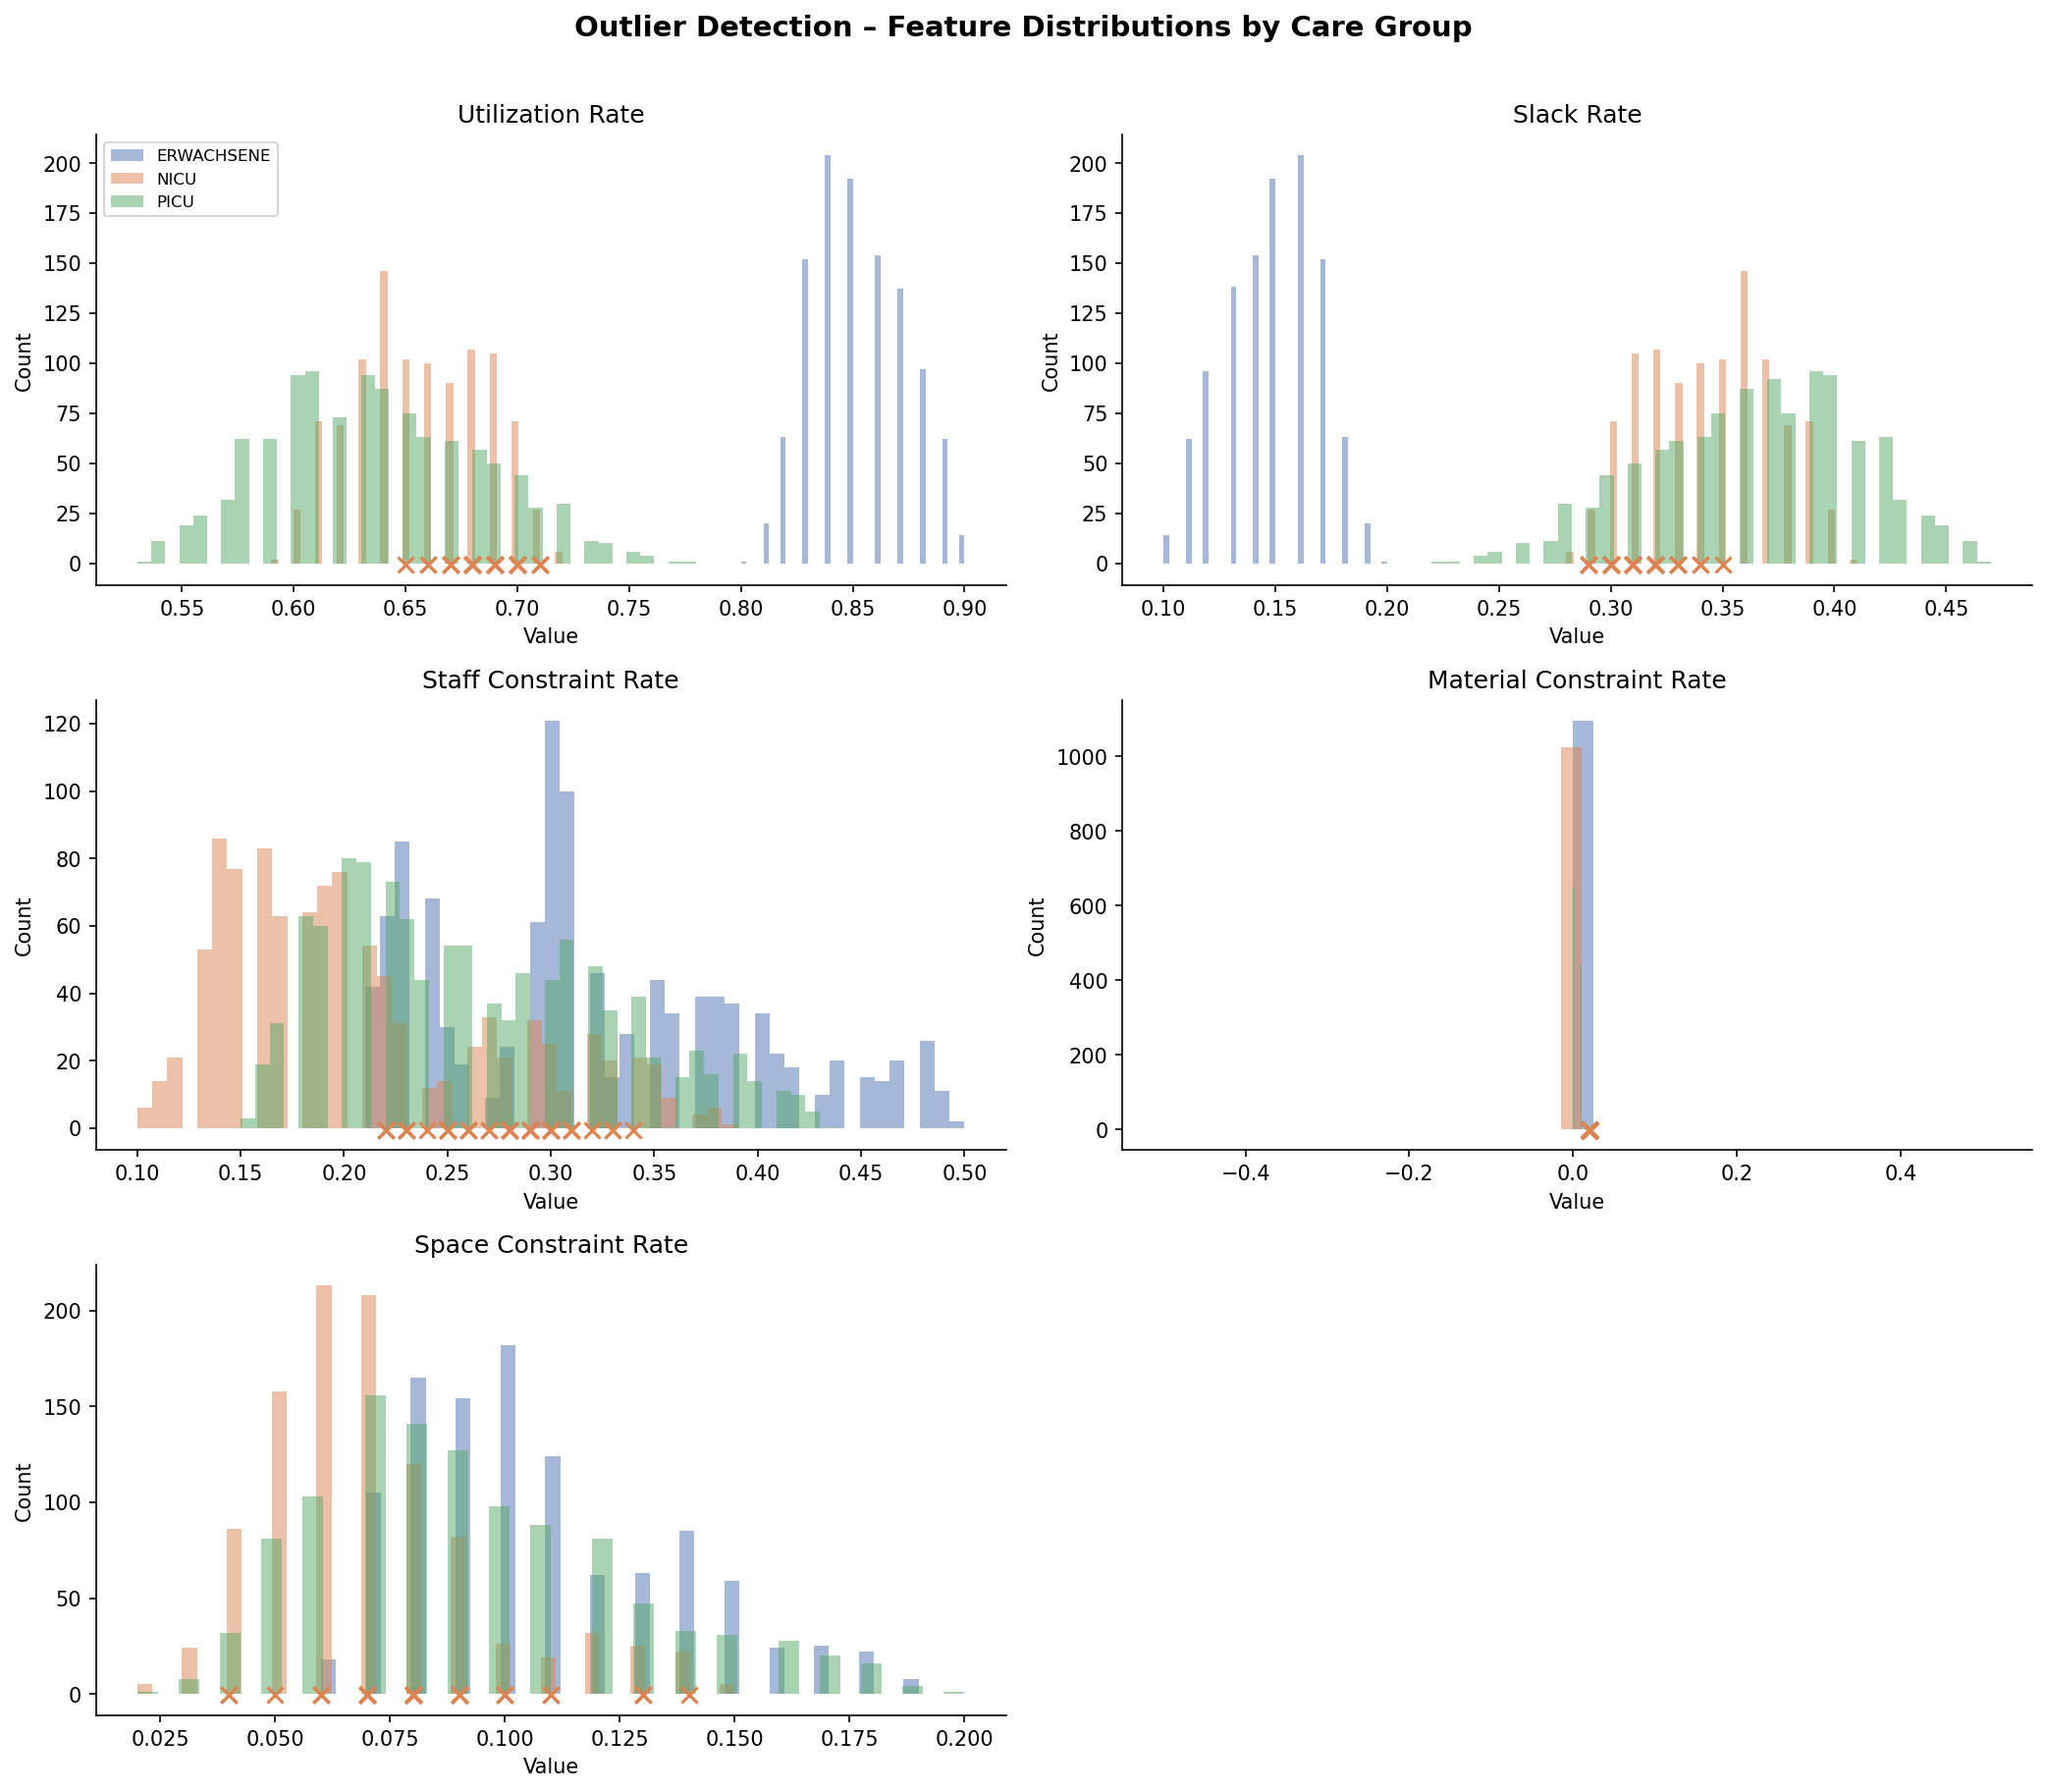

In [48]:
"""
=============================================================
ICU Capacity Strain – Outlier Detection & Robustness Testing
=============================================================
Sarah Busch – MSc BIT Management Thesis
=============================================================
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy import stats
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import warnings
warnings.filterwarnings("ignore")

# ── Plotting style ─────────────────────────────────────────
plt.rcParams.update({
    "figure.dpi": 150,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.family": "sans-serif",
    "axes.titlesize": 12,
    "axes.labelsize": 10,
})
PALETTE = {"ERWACHSENE": "#4C72B0", "NICU": "#DD8452", "PICU": "#55A868"}

# ═══════════════════════════════════════════════════════════
# 1. LOAD & CLEAN
# ═══════════════════════════════════════════════════════════
print("=" * 60)
print("STEP 1 – Loading and cleaning data")
print("=" * 60)

df = pd.read_csv(
    "Intensivregister_updated.csv",
    sep=";",
    decimal=",",
    encoding="utf-8-sig",
)

df.columns = df.columns.str.strip()
df["date"] = pd.to_datetime(df["date"], dayfirst=True)
df = df[df["date"] >= "2022-01-01"].copy()
df = df.sort_values(["care_group", "date"]).reset_index(drop=True)

# Drop COVID columns
covid_cols = [c for c in df.columns if "covid" in c.lower()]
df.drop(columns=covid_cols, inplace=True)

FEATURE_COLS = [
    "utilization_rate",
    "slack_rate",
    "staff_constraint_rate",
    "material_constraint_rate",
    "space_constraint_rate",
]

# Clip rates to [0, 1] – reporting artefacts can push above 1
for col in FEATURE_COLS:
    df[col] = df[col].clip(0, 1)

print(f"Rows after 2022 filter: {len(df)}")
print(f"Care groups : {df['care_group'].unique()}")
print(f"Date range  : {df['date'].min().date()} → {df['date'].max().date()}")
print(f"Missing values:\n{df[FEATURE_COLS].isna().sum()}\n")

# ═══════════════════════════════════════════════════════════
# 2. OUTLIER DETECTION – three complementary methods
# ═══════════════════════════════════════════════════════════
print("=" * 60)
print("STEP 2 – Outlier Detection")
print("=" * 60)

results = {}          # per care_group summary
outlier_flags = []    # rows flagged by any method

for group, gdf in df.groupby("care_group"):
    X = gdf[FEATURE_COLS].dropna()
    idx = X.index

    # ── Method A: IQR (per variable, 3× IQR = extreme outliers) ──
    iqr_flags = pd.Series(False, index=idx)
    for col in FEATURE_COLS:
        q1, q3 = X[col].quantile(0.25), X[col].quantile(0.75)
        iqr = q3 - q1
        lo, hi = q1 - 3 * iqr, q3 + 3 * iqr
        iqr_flags |= (X[col] < lo) | (X[col] > hi)

    # ── Method B: Z-score  (|z| > 3.5) ──
    z_flags = pd.Series(False, index=idx)
    for col in FEATURE_COLS:
        z = np.abs(stats.zscore(X[col].fillna(X[col].median())))
        z_flags |= (z > 3.5)

    # ── Method C: Isolation Forest (multivariate) ──
    scaler = StandardScaler()
    X_sc = scaler.fit_transform(X.fillna(X.median()))
    iso = IsolationForest(contamination=0.03, random_state=42, n_jobs=-1)
    iso_pred = iso.fit_predict(X_sc)          # -1 = outlier
    iso_flags = pd.Series(iso_pred == -1, index=idx)
    iso_scores = iso.decision_function(X_sc)  # lower = more anomalous

    # ── Consensus flag: ≥ 2 methods agree ──
    consensus = (iqr_flags.astype(int) +
                 z_flags.astype(int) +
                 iso_flags.astype(int)) >= 2

    # Store enriched rows
    tmp = gdf.loc[idx].copy()
    tmp["flag_iqr"]       = iqr_flags.values
    tmp["flag_zscore"]    = z_flags.values
    tmp["flag_isoforest"] = iso_flags.values
    tmp["flag_consensus"] = consensus.values
    tmp["anomaly_score"]  = iso_scores
    outlier_flags.append(tmp)

    n_total    = len(X)
    n_iqr      = iqr_flags.sum()
    n_z        = z_flags.sum()
    n_iso      = iso_flags.sum()
    n_consensus= consensus.sum()

    results[group] = {
        "N": n_total,
        "IQR outliers":        n_iqr,
        "Z-score outliers":    n_z,
        "IsoForest outliers":  n_iso,
        "Consensus outliers":  n_consensus,
        "% consensus":         round(100 * n_consensus / n_total, 1),
    }

    print(f"\n{group}  (n={n_total})")
    print(f"  IQR (3×)         : {n_iqr}  ({100*n_iqr/n_total:.1f}%)")
    print(f"  Z-score (>3.5)   : {n_z}  ({100*n_z/n_total:.1f}%)")
    print(f"  Isolation Forest : {n_iso}  ({100*n_iso/n_total:.1f}%)")
    print(f"  ── Consensus ≥2  : {n_consensus}  ({100*n_consensus/n_total:.1f}%)")

outlier_df = pd.concat(outlier_flags).reset_index(drop=True)

# Show the 10 most anomalous days overall
print("\nTop 10 most anomalous observations (lowest IsoForest score):")
top10 = (outlier_df.nsmallest(10, "anomaly_score")
         [["date","care_group","anomaly_score"] + FEATURE_COLS])
print(top10.to_string(index=False))

# ═══════════════════════════════════════════════════════════
# 3. OUTLIER VISUALISATION
# ═══════════════════════════════════════════════════════════
print("\n" + "=" * 60)
print("STEP 3 – Plotting outlier diagnostics")
print("=" * 60)

fig, axes = plt.subplots(3, 2, figsize=(14, 12))
fig.suptitle("Outlier Detection – Feature Distributions by Care Group",
             fontsize=14, fontweight="bold", y=1.01)

for ax, col in zip(axes.flat, FEATURE_COLS):
    for group, color in PALETTE.items():
        sub = outlier_df[outlier_df["care_group"] == group]
        clean   = sub.loc[~sub["flag_consensus"], col]
        flagged = sub.loc[ sub["flag_consensus"], col]
        ax.hist(clean,   bins=40, alpha=0.5, color=color, label=group)
        ax.scatter(flagged, np.zeros(len(flagged)) - 0.5,
                   color=color, marker="x", s=60, zorder=5)
    ax.set_title(col.replace("_", " ").title())
    ax.set_xlabel("Value")
    ax.set_ylabel("Count")

axes.flat[-1].set_visible(False)  # hide 6th panel (only 5 features)
axes.flat[0].legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig("/mnt/user-data/outputs/01_outlier_distributions.png",
            bbox_inches="tight")
plt.close()
print("  Saved → 01_outlier_distributions.png")

# ── Time-series view of anomaly score ──
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=False)
fig.suptitle("Isolation Forest Anomaly Score Over Time\n"
             "(lower = more anomalous; red = consensus outlier)",
             fontsize=13, fontweight="bold")

for ax, (group, color) in zip(axes, PALETTE.items()):
    sub = outlier_df[outlier_df["care_group"] == group].sort_values("date")
    normal  = sub[~sub["flag_consensus"]]
    flagged = sub[ sub["flag_consensus"]]
    ax.plot(normal["date"],  normal["anomaly_score"],
            color=color, lw=0.8, alpha=0.7, label="Normal")
    ax.scatter(flagged["date"], flagged["anomaly_score"],
               color="crimson", s=30, zorder=5, label="Consensus outlier")
    ax.axhline(0, color="black", lw=0.6, linestyle="--", alpha=0.5)
    ax.set_title(group)
    ax.set_ylabel("Anomaly score")
    ax.legend(fontsize=8)

axes[-1].set_xlabel("Date")
plt.tight_layout()
plt.savefig("/mnt/user-data/outputs/02_anomaly_score_timeseries.png",
            bbox_inches="tight")
plt.close()
print("  Saved → 02_anomaly_score_timeseries.png")

# ── Boxplots: outlier vs. clean ──
fig, axes = plt.subplots(1, len(FEATURE_COLS), figsize=(16, 5))
fig.suptitle("Feature Values: Clean vs. Consensus Outliers (all groups)",
             fontsize=12, fontweight="bold")

for ax, col in zip(axes, FEATURE_COLS):
    plot_data = [
        outlier_df.loc[~outlier_df["flag_consensus"], col].dropna(),
        outlier_df.loc[ outlier_df["flag_consensus"], col].dropna(),
    ]
    bp = ax.boxplot(plot_data, patch_artist=True, widths=0.5,
                    labels=["Clean", "Outlier"])
    bp["boxes"][0].set_facecolor("#AED6F1")
    bp["boxes"][1].set_facecolor("#F1948A")
    ax.set_title(col.replace("_","\n").title(), fontsize=9)
    ax.set_ylabel("Value")

plt.tight_layout()
plt.savefig("/mnt/user-data/outputs/03_outlier_boxplots.png",
            bbox_inches="tight")
plt.close()
print("  Saved → 03_outlier_boxplots.png")

# ── Heatmap: constraint co-occurrence in consensus outliers ──
flagged_all = outlier_df[outlier_df["flag_consensus"]]
constraint_cols = ["staff_constraint_rate",
                   "material_constraint_rate",
                   "space_constraint_rate"]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
fig.suptitle("Constraint Co-occurrence in Consensus Outlier Days",
             fontsize=12, fontweight="bold")

for ax, group in zip(axes, PALETTE.keys()):
    sub = flagged_all[flagged_all["care_group"] == group][constraint_cols]
    if sub.empty:
        ax.set_title(f"{group}\n(no outliers)")
        continue
    corr = sub.corr()
    sns.heatmap(corr, ax=ax, annot=True, fmt=".2f", cmap="coolwarm",
                vmin=-1, vmax=1, square=True,
                xticklabels=[c.split("_")[0] for c in constraint_cols],
                yticklabels=[c.split("_")[0] for c in constraint_cols])
    ax.set_title(f"{group}\n(n={len(sub)})")

plt.tight_layout()
plt.savefig("/mnt/user-data/outputs/04_outlier_constraint_heatmap.png",
            bbox_inches="tight")
plt.close()
print("  Saved → 04_outlier_constraint_heatmap.png")

# ═══════════════════════════════════════════════════════════
# 4. ROBUSTNESS TEST – Clustering stability with / without outliers
# ═══════════════════════════════════════════════════════════
print("\n" + "=" * 60)
print("STEP 4 – Robustness Test: Clustering With vs. Without Outliers")
print("=" * 60)

K_RANGE = range(2, 7)
robustness_rows = []

for group in df["care_group"].unique():
    sub_full    = outlier_df[outlier_df["care_group"] == group]
    sub_clean   = sub_full[~sub_full["flag_consensus"]]

    # Also test winsorized version (1st / 99th percentile)
    sub_winsor  = sub_full.copy()
    for col in FEATURE_COLS:
        lo, hi = sub_winsor[col].quantile(0.01), sub_winsor[col].quantile(0.99)
        sub_winsor[col] = sub_winsor[col].clip(lo, hi)

    datasets = {
        "Full (with outliers)":     sub_full[FEATURE_COLS].fillna(0),
        "Cleaned (outliers removed)": sub_clean[FEATURE_COLS].fillna(0),
        "Winsorized (1–99%)":       sub_winsor[FEATURE_COLS].fillna(0),
    }

    print(f"\n  {group}")
    for version, X_raw in datasets.items():
        scaler = StandardScaler()
        X_sc   = scaler.fit_transform(X_raw)

        sil_scores = {}
        for k in K_RANGE:
            km = KMeans(n_clusters=k, random_state=42, n_init=10)
            labels = km.fit_predict(X_sc)
            if len(set(labels)) > 1:
                sil_scores[k] = round(silhouette_score(X_sc, labels), 4)
            else:
                sil_scores[k] = np.nan

        best_k   = max(sil_scores, key=lambda k: sil_scores[k] or -1)
        best_sil = sil_scores[best_k]

        robustness_rows.append({
            "care_group":  group,
            "version":     version,
            "best_k":      best_k,
            "best_silhouette": best_sil,
            **{f"sil_k{k}": v for k, v in sil_scores.items()},
        })
        print(f"    [{version}]  best k={best_k}, silhouette={best_sil:.4f}")
        print(f"      All scores: { {k: round(v,3) for k,v in sil_scores.items()} }")

rob_df = pd.DataFrame(robustness_rows)

# ═══════════════════════════════════════════════════════════
# 5. ROBUSTNESS VISUALISATION
# ═══════════════════════════════════════════════════════════
print("\n" + "=" * 60)
print("STEP 5 – Plotting robustness results")
print("=" * 60)

sil_cols = [f"sil_k{k}" for k in K_RANGE]
groups   = rob_df["care_group"].unique()
versions = rob_df["version"].unique()
colors   = {"Full (with outliers)": "#E74C3C",
            "Cleaned (outliers removed)": "#2ECC71",
            "Winsorized (1–99%)": "#3498DB"}
markers  = {"Full (with outliers)": "o",
            "Cleaned (outliers removed)": "s",
            "Winsorized (1–99%)": "^"}

fig, axes = plt.subplots(1, len(groups), figsize=(15, 5), sharey=True)
fig.suptitle("Robustness Test: Silhouette Score vs. k\n"
             "across Full / Cleaned / Winsorized datasets",
             fontsize=13, fontweight="bold")

for ax, group in zip(axes, groups):
    sub = rob_df[rob_df["care_group"] == group]
    for _, row in sub.iterrows():
        v    = row["version"]
        vals = [row[c] for c in sil_cols]
        ax.plot(list(K_RANGE), vals,
                label=v, color=colors[v], marker=markers[v],
                lw=2, ms=7)
        # Mark best k
        best_idx = int(row["best_k"]) - min(K_RANGE)
        ax.scatter(row["best_k"], vals[best_idx],
                   color=colors[v], s=120, zorder=6,
                   edgecolors="black", linewidths=1.2)

    ax.set_title(group)
    ax.set_xlabel("Number of clusters (k)")
    ax.set_xticks(list(K_RANGE))
    ax.set_ylabel("Silhouette Score" if ax == axes[0] else "")
    ax.grid(axis="y", alpha=0.3)

handles, labels = axes[0].get_legend_handles_labels()
# Deduplicate
seen = {}
for h, l in zip(handles, labels):
    seen[l] = h
fig.legend(seen.values(), seen.keys(),
           loc="lower center", ncol=3, fontsize=9,
           bbox_to_anchor=(0.5, -0.12))

plt.tight_layout()
plt.savefig("/mnt/user-data/outputs/05_robustness_silhouette.png",
            bbox_inches="tight")
plt.close()
print("  Saved → 05_robustness_silhouette.png")

# ── Summary table ──
summary_pivot = rob_df.pivot_table(
    index="version", columns="care_group",
    values=["best_k", "best_silhouette"]
).round(4)

print("\nRobustness Summary Table:")
print(summary_pivot.to_string())

# ═══════════════════════════════════════════════════════════
# 6. EXPORT FLAGGED DATASET
# ═══════════════════════════════════════════════════════════
out_path = "/mnt/user-data/outputs/intensivregister_outlier_flagged.csv"
outlier_df.to_csv(out_path, index=False)
print(f"\nFlagged dataset exported → {out_path}")

print("\n" + "=" * 60)
print("ALL DONE")
print("=" * 60)
print("""
Output files:
  01_outlier_distributions.png   – Feature histograms, outliers marked
  02_anomaly_score_timeseries.png – Anomaly score over time
  03_outlier_boxplots.png        – Clean vs. outlier feature comparison
  04_outlier_constraint_heatmap.png – Constraint co-occurrence in outliers
  05_robustness_silhouette.png   – Clustering stability across treatments
  intensivregister_outlier_flagged.csv – Dataset with outlier flags
""")

In [52]:
"""
=============================================================
ICU Capacity Strain – Outlier Detection & Robustness Testing
=============================================================
Sarah Busch – MSc BIT Management Thesis
=============================================================
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy import stats
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import warnings
import os
warnings.filterwarnings("ignore")

# ── Create output directory if it doesn't exist ────────────
os.makedirs("/mnt/user-data/outputs", exist_ok=True)

# ── Plotting style ─────────────────────────────────────────
plt.rcParams.update({
    "figure.dpi": 150,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.family": "sans-serif",
    "axes.titlesize": 12,
    "axes.labelsize": 10,
})
PALETTE = {"ERWACHSENE": "#4C72B0", "NICU": "#DD8452", "PICU": "#55A868"}

# ═══════════════════════════════════════════════════════════
# 1. LOAD & CLEAN
# ═══════════════════════════════════════════════════════════
print("=" * 60)
print("STEP 1 – Loading and cleaning data")
print("=" * 60)

df = pd.read_csv(
    "/mnt/project/Intensivregister_updated.csv",
    sep=";",
    decimal=",",
    encoding="utf-8-sig",
)

df.columns = df.columns.str.strip()
df["date"] = pd.to_datetime(df["date"], dayfirst=True)
df = df[df["date"] >= "2022-01-01"].copy()
df = df.sort_values(["care_group", "date"]).reset_index(drop=True)

# Drop COVID columns
covid_cols = [c for c in df.columns if "covid" in c.lower()]
df.drop(columns=covid_cols, inplace=True)

FEATURE_COLS = [
    "utilization_rate",
    "slack_rate",
    "staff_constraint_rate",
    "material_constraint_rate",
    "space_constraint_rate",
]

# Clip rates to [0, 1] – reporting artefacts can push above 1
for col in FEATURE_COLS:
    df[col] = df[col].clip(0, 1)

print(f"Rows after 2022 filter: {len(df)}")
print(f"Care groups : {df['care_group'].unique()}")
print(f"Date range  : {df['date'].min().date()} → {df['date'].max().date()}")
print(f"Missing values:\n{df[FEATURE_COLS].isna().sum()}\n")

# ═══════════════════════════════════════════════════════════
# 2. OUTLIER DETECTION – three complementary methods
# ═══════════════════════════════════════════════════════════
print("=" * 60)
print("STEP 2 – Outlier Detection")
print("=" * 60)

results = {}          # per care_group summary
outlier_flags = []    # rows flagged by any method

for group, gdf in df.groupby("care_group"):
    X = gdf[FEATURE_COLS].dropna()
    idx = X.index

    # ── Method A: IQR (per variable, 3× IQR = extreme outliers) ──
    iqr_flags = pd.Series(False, index=idx)
    for col in FEATURE_COLS:
        q1, q3 = X[col].quantile(0.25), X[col].quantile(0.75)
        iqr = q3 - q1
        lo, hi = q1 - 3 * iqr, q3 + 3 * iqr
        iqr_flags |= (X[col] < lo) | (X[col] > hi)

    # ── Method B: Z-score  (|z| > 3.5) ──
    z_flags = pd.Series(False, index=idx)
    for col in FEATURE_COLS:
        z = np.abs(stats.zscore(X[col].fillna(X[col].median())))
        z_flags |= (z > 3.5)

    # ── Method C: Isolation Forest (multivariate) ──
    scaler = StandardScaler()
    X_sc = scaler.fit_transform(X.fillna(X.median()))
    iso = IsolationForest(contamination=0.03, random_state=42, n_jobs=-1)
    iso_pred = iso.fit_predict(X_sc)          # -1 = outlier
    iso_flags = pd.Series(iso_pred == -1, index=idx)
    iso_scores = iso.decision_function(X_sc)  # lower = more anomalous

    # ── Consensus flag: ≥ 2 methods agree ──
    consensus = (iqr_flags.astype(int) +
                 z_flags.astype(int) +
                 iso_flags.astype(int)) >= 2

    # Store enriched rows
    tmp = gdf.loc[idx].copy()
    tmp["flag_iqr"]       = iqr_flags.values
    tmp["flag_zscore"]    = z_flags.values
    tmp["flag_isoforest"] = iso_flags.values
    tmp["flag_consensus"] = consensus.values
    tmp["anomaly_score"]  = iso_scores
    outlier_flags.append(tmp)

    n_total    = len(X)
    n_iqr      = iqr_flags.sum()
    n_z        = z_flags.sum()
    n_iso      = iso_flags.sum()
    n_consensus= consensus.sum()

    results[group] = {
        "N": n_total,
        "IQR outliers":        n_iqr,
        "Z-score outliers":    n_z,
        "IsoForest outliers":  n_iso,
        "Consensus outliers":  n_consensus,
        "% consensus":         round(100 * n_consensus / n_total, 1),
    }

    print(f"\n{group}  (n={n_total})")
    print(f"  IQR (3×)         : {n_iqr}  ({100*n_iqr/n_total:.1f}%)")
    print(f"  Z-score (>3.5)   : {n_z}  ({100*n_z/n_total:.1f}%)")
    print(f"  Isolation Forest : {n_iso}  ({100*n_iso/n_total:.1f}%)")
    print(f"  ── Consensus ≥2  : {n_consensus}  ({100*n_consensus/n_total:.1f}%)")

outlier_df = pd.concat(outlier_flags).reset_index(drop=True)

# Show the 10 most anomalous days overall
print("\nTop 10 most anomalous observations (lowest IsoForest score):")
top10 = (outlier_df.nsmallest(10, "anomaly_score")
         [["date","care_group","anomaly_score"] + FEATURE_COLS])
print(top10.to_string(index=False))

# ═══════════════════════════════════════════════════════════
# 3. OUTLIER VISUALISATION
# ═══════════════════════════════════════════════════════════
print("\n" + "=" * 60)
print("STEP 3 – Plotting outlier diagnostics")
print("=" * 60)

fig, axes = plt.subplots(3, 2, figsize=(14, 12))
fig.suptitle("Outlier Detection – Feature Distributions by Care Group",
             fontsize=14, fontweight="bold", y=1.01)

for ax, col in zip(axes.flat, FEATURE_COLS):
    for group, color in PALETTE.items():
        sub = outlier_df[outlier_df["care_group"] == group]
        clean   = sub.loc[~sub["flag_consensus"], col]
        flagged = sub.loc[ sub["flag_consensus"], col]
        ax.hist(clean,   bins=40, alpha=0.5, color=color, label=group)
        ax.scatter(flagged, np.zeros(len(flagged)) - 0.5,
                   color=color, marker="x", s=60, zorder=5)
    ax.set_title(col.replace("_", " ").title())
    ax.set_xlabel("Value")
    ax.set_ylabel("Count")

axes.flat[-1].set_visible(False)  # hide 6th panel (only 5 features)
axes.flat[0].legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig("/mnt/user-data/outputs/01_outlier_distributions.png",
            bbox_inches="tight")
plt.close()
print("  Saved → 01_outlier_distributions.png")

# ── Time-series view of anomaly score ──
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=False)
fig.suptitle("Isolation Forest Anomaly Score Over Time\n"
             "(lower = more anomalous; red = consensus outlier)",
             fontsize=13, fontweight="bold")

for ax, (group, color) in zip(axes, PALETTE.items()):
    sub = outlier_df[outlier_df["care_group"] == group].sort_values("date")
    normal  = sub[~sub["flag_consensus"]]
    flagged = sub[ sub["flag_consensus"]]
    ax.plot(normal["date"],  normal["anomaly_score"],
            color=color, lw=0.8, alpha=0.7, label="Normal")
    ax.scatter(flagged["date"], flagged["anomaly_score"],
               color="crimson", s=30, zorder=5, label="Consensus outlier")
    ax.axhline(0, color="black", lw=0.6, linestyle="--", alpha=0.5)
    ax.set_title(group)
    ax.set_ylabel("Anomaly score")
    ax.legend(fontsize=8)

axes[-1].set_xlabel("Date")
plt.tight_layout()
plt.savefig("/mnt/user-data/outputs/02_anomaly_score_timeseries.png",
            bbox_inches="tight")
plt.close()
print("  Saved → 02_anomaly_score_timeseries.png")

# ── Boxplots: outlier vs. clean ──
fig, axes = plt.subplots(1, len(FEATURE_COLS), figsize=(16, 5))
fig.suptitle("Feature Values: Clean vs. Consensus Outliers (all groups)",
             fontsize=12, fontweight="bold")

for ax, col in zip(axes, FEATURE_COLS):
    plot_data = [
        outlier_df.loc[~outlier_df["flag_consensus"], col].dropna(),
        outlier_df.loc[ outlier_df["flag_consensus"], col].dropna(),
    ]
    bp = ax.boxplot(plot_data, patch_artist=True, widths=0.5,
                    labels=["Clean", "Outlier"])
    bp["boxes"][0].set_facecolor("#AED6F1")
    bp["boxes"][1].set_facecolor("#F1948A")
    ax.set_title(col.replace("_","\n").title(), fontsize=9)
    ax.set_ylabel("Value")

plt.tight_layout()
plt.savefig("/mnt/user-data/outputs/03_outlier_boxplots.png",
            bbox_inches="tight")
plt.close()
print("  Saved → 03_outlier_boxplots.png")

# ── Heatmap: constraint co-occurrence in consensus outliers ──
flagged_all = outlier_df[outlier_df["flag_consensus"]]
constraint_cols = ["staff_constraint_rate",
                   "material_constraint_rate",
                   "space_constraint_rate"]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
fig.suptitle("Constraint Co-occurrence in Consensus Outlier Days",
             fontsize=12, fontweight="bold")

for ax, group in zip(axes, PALETTE.keys()):
    sub = flagged_all[flagged_all["care_group"] == group][constraint_cols]
    if sub.empty:
        ax.set_title(f"{group}\n(no outliers)")
        continue
    corr = sub.corr()
    sns.heatmap(corr, ax=ax, annot=True, fmt=".2f", cmap="coolwarm",
                vmin=-1, vmax=1, square=True,
                xticklabels=[c.split("_")[0] for c in constraint_cols],
                yticklabels=[c.split("_")[0] for c in constraint_cols])
    ax.set_title(f"{group}\n(n={len(sub)})")

plt.tight_layout()
plt.savefig("/mnt/user-data/outputs/04_outlier_constraint_heatmap.png",
            bbox_inches="tight")
plt.close()
print("  Saved → 04_outlier_constraint_heatmap.png")

# ═══════════════════════════════════════════════════════════
# 4. ROBUSTNESS TEST – Clustering stability with / without outliers
# ═══════════════════════════════════════════════════════════
print("\n" + "=" * 60)
print("STEP 4 – Robustness Test: Clustering With vs. Without Outliers")
print("=" * 60)

K_RANGE = range(2, 7)
robustness_rows = []

for group in df["care_group"].unique():
    sub_full    = outlier_df[outlier_df["care_group"] == group]
    sub_clean   = sub_full[~sub_full["flag_consensus"]]

    # Also test winsorized version (1st / 99th percentile)
    sub_winsor  = sub_full.copy()
    for col in FEATURE_COLS:
        lo, hi = sub_winsor[col].quantile(0.01), sub_winsor[col].quantile(0.99)
        sub_winsor[col] = sub_winsor[col].clip(lo, hi)

    datasets = {
        "Full (with outliers)":     sub_full[FEATURE_COLS].fillna(0),
        "Cleaned (outliers removed)": sub_clean[FEATURE_COLS].fillna(0),
        "Winsorized (1–99%)":       sub_winsor[FEATURE_COLS].fillna(0),
    }

    print(f"\n  {group}")
    for version, X_raw in datasets.items():
        scaler = StandardScaler()
        X_sc   = scaler.fit_transform(X_raw)

        sil_scores = {}
        for k in K_RANGE:
            km = KMeans(n_clusters=k, random_state=42, n_init=10)
            labels = km.fit_predict(X_sc)
            if len(set(labels)) > 1:
                sil_scores[k] = round(silhouette_score(X_sc, labels), 4)
            else:
                sil_scores[k] = np.nan

        best_k   = max(sil_scores, key=lambda k: sil_scores[k] or -1)
        best_sil = sil_scores[best_k]

        robustness_rows.append({
            "care_group":  group,
            "version":     version,
            "best_k":      best_k,
            "best_silhouette": best_sil,
            **{f"sil_k{k}": v for k, v in sil_scores.items()},
        })
        print(f"    [{version}]  best k={best_k}, silhouette={best_sil:.4f}")
        print(f"      All scores: { {k: round(v,3) for k,v in sil_scores.items()} }")

rob_df = pd.DataFrame(robustness_rows)

# ═══════════════════════════════════════════════════════════
# 5. ROBUSTNESS VISUALISATION
# ═══════════════════════════════════════════════════════════
print("\n" + "=" * 60)
print("STEP 5 – Plotting robustness results")
print("=" * 60)

sil_cols = [f"sil_k{k}" for k in K_RANGE]
groups   = rob_df["care_group"].unique()
versions = rob_df["version"].unique()
colors   = {"Full (with outliers)": "#E74C3C",
            "Cleaned (outliers removed)": "#2ECC71",
            "Winsorized (1–99%)": "#3498DB"}
markers  = {"Full (with outliers)": "o",
            "Cleaned (outliers removed)": "s",
            "Winsorized (1–99%)": "^"}

fig, axes = plt.subplots(1, len(groups), figsize=(15, 5), sharey=True)
fig.suptitle("Robustness Test: Silhouette Score vs. k\n"
             "across Full / Cleaned / Winsorized datasets",
             fontsize=13, fontweight="bold")

for ax, group in zip(axes, groups):
    sub = rob_df[rob_df["care_group"] == group]
    for _, row in sub.iterrows():
        v    = row["version"]
        vals = [row[c] for c in sil_cols]
        ax.plot(list(K_RANGE), vals,
                label=v, color=colors[v], marker=markers[v],
                lw=2, ms=7)
        # Mark best k
        best_idx = int(row["best_k"]) - min(K_RANGE)
        ax.scatter(row["best_k"], vals[best_idx],
                   color=colors[v], s=120, zorder=6,
                   edgecolors="black", linewidths=1.2)

    ax.set_title(group)
    ax.set_xlabel("Number of clusters (k)")
    ax.set_xticks(list(K_RANGE))
    ax.set_ylabel("Silhouette Score" if ax == axes[0] else "")
    ax.grid(axis="y", alpha=0.3)

handles, labels = axes[0].get_legend_handles_labels()
# Deduplicate
seen = {}
for h, l in zip(handles, labels):
    seen[l] = h
fig.legend(seen.values(), seen.keys(),
           loc="lower center", ncol=3, fontsize=9,
           bbox_to_anchor=(0.5, -0.12))

plt.tight_layout()
plt.savefig("/mnt/user-data/outputs/05_robustness_silhouette.png",
            bbox_inches="tight")
plt.close()
print("  Saved → 05_robustness_silhouette.png")

# ── Summary table ──
summary_pivot = rob_df.pivot_table(
    index="version", columns="care_group",
    values=["best_k", "best_silhouette"]
).round(4)

print("\nRobustness Summary Table:")
print(summary_pivot.to_string())

# ═══════════════════════════════════════════════════════════
# 6. EXPORT FLAGGED DATASET
# ═══════════════════════════════════════════════════════════
out_path = "/mnt/user-data/outputs/intensivregister_outlier_flagged.csv"
outlier_df.to_csv(out_path, index=False)
print(f"\nFlagged dataset exported → {out_path}")

print("\n" + "=" * 60)
print("ALL DONE")
print("=" * 60)
print("""
Output files:
  01_outlier_distributions.png   – Feature histograms, outliers marked
  02_anomaly_score_timeseries.png – Anomaly score over time
  03_outlier_boxplots.png        – Clean vs. outlier feature comparison
  04_outlier_constraint_heatmap.png – Constraint co-occurrence in outliers
  05_robustness_silhouette.png   – Clustering stability across treatments
  intensivregister_outlier_flagged.csv – Dataset with outlier flags
""")

OSError: [Errno 30] Read-only file system: '/mnt'